In [1]:
# ============================================
# RETAILPULSE - DATA CLEANING
# ============================================

import pandas as pd
import numpy as np
import os
import warnings
warnings.filterwarnings('ignore')

import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.figsize'] = (12, 6)

print("✅ Libraries imported!")

# ============================================
# LOAD DATA (bulletproof paths)
# ============================================
current_dir = os.getcwd()
if os.path.basename(current_dir) == "notebooks":
    project_root = os.path.abspath(os.path.join(current_dir, ".."))
else:
    project_root = os.path.abspath(current_dir)

parquet_path = os.path.join(project_root, "data", "processed", "online_retail_combined.parquet")

print(f"📂 Loading data...")
df = pd.read_parquet(parquet_path)

# Fix data types
df['Invoice'] = df['Invoice'].astype(str)
df['StockCode'] = df['StockCode'].astype(str)
df['Description'] = df['Description'].astype(str)
df['Country'] = df['Country'].astype(str)
df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'])

print(f"✅ Loaded {len(df):,} rows × {len(df.columns)} columns")
print(f"📅 Date range: {df['InvoiceDate'].min().date()} to {df['InvoiceDate'].max().date()}")
print()

# Keep track of how many rows we remove at each step
# This is important for your project report!
cleaning_log = []
cleaning_log.append(("Original Dataset", len(df)))

print("📋 CLEANING LOG:")
print(f"   Starting rows: {len(df):,}")

✅ Libraries imported!
📂 Loading data...
✅ Loaded 1,067,371 rows × 8 columns
📅 Date range: 2009-12-01 to 2011-12-09

📋 CLEANING LOG:
   Starting rows: 1,067,371


In [2]:
# ============================================
# STEP 1: REMOVE DUPLICATE ROWS
# ============================================

print("🔍 CHECKING FOR DUPLICATES...")
print("-" * 50)

# Check for exact duplicate rows (all columns identical)
duplicates = df.duplicated()
num_duplicates = duplicates.sum()

print(f"   Exact duplicate rows found: {num_duplicates:,}")
print(f"   Percentage of total: {num_duplicates/len(df)*100:.2f}%")

if num_duplicates > 0:
    # Remove duplicates, keeping the first occurrence
    df = df.drop_duplicates(keep='first').reset_index(drop=True)
    print(f"   ✅ Removed {num_duplicates:,} duplicate rows")
else:
    print(f"   ✅ No duplicates to remove")

cleaning_log.append(("After Removing Duplicates", len(df)))
print(f"\n   📊 Rows remaining: {len(df):,}")

🔍 CHECKING FOR DUPLICATES...
--------------------------------------------------
   Exact duplicate rows found: 34,335
   Percentage of total: 3.22%
   ✅ Removed 34,335 duplicate rows

   📊 Rows remaining: 1,033,036


In [3]:
# ============================================
# STEP 2: REMOVE CANCELLED ORDERS
# ============================================

print("🔍 CHECKING FOR CANCELLED ORDERS...")
print("-" * 50)

# Identify cancelled invoices (Invoice starts with 'C')
cancelled_mask = df['Invoice'].str.startswith('C', na=False)
num_cancelled = cancelled_mask.sum()

print(f"   Cancelled orders found: {num_cancelled:,}")
print(f"   Percentage of total: {num_cancelled/len(df)*100:.2f}%")
print()

# Show some examples of cancelled orders
print("   📌 Examples of cancelled invoices:")
cancelled_examples = df[cancelled_mask].head(3)
for _, row in cancelled_examples.iterrows():
    print(f"      Invoice: {row['Invoice']}, Qty: {row['Quantity']}, "
          f"Price: £{row['Price']:.2f}, Desc: {row['Description'][:35]}")
print()

# Save cancelled orders separately (useful for return analysis later)
cancelled_df = df[cancelled_mask].copy()
cancelled_path = os.path.join(project_root, "data", "processed", "cancelled_orders.csv")
cancelled_df.to_csv(cancelled_path, index=False)
print(f"   💾 Saved cancelled orders to: {cancelled_path}")

# Remove cancelled orders from main dataset
df = df[~cancelled_mask].reset_index(drop=True)
print(f"   ✅ Removed {num_cancelled:,} cancelled orders")

cleaning_log.append(("After Removing Cancelled Orders", len(df)))
print(f"\n   📊 Rows remaining: {len(df):,}")

🔍 CHECKING FOR CANCELLED ORDERS...
--------------------------------------------------
   Cancelled orders found: 19,104
   Percentage of total: 1.85%

   📌 Examples of cancelled invoices:
      Invoice: C489449, Qty: -12, Price: £2.95, Desc: PAPER BUNTING WHITE LACE
      Invoice: C489449, Qty: -6, Price: £1.65, Desc: CREAM FELT EASTER EGG BASKET
      Invoice: C489449, Qty: -4, Price: £4.25, Desc: POTTING SHED SOW 'N' GROW SET

   💾 Saved cancelled orders to: d:\Zudio Internship\Project 1\RetailPulse\data\processed\cancelled_orders.csv
   ✅ Removed 19,104 cancelled orders

   📊 Rows remaining: 1,013,932


In [4]:
# ============================================
# STEP 3: REMOVE NEGATIVE & ZERO QUANTITIES
# ============================================

print("🔍 CHECKING QUANTITY ISSUES...")
print("-" * 50)

# Count negative quantities
neg_qty = (df['Quantity'] < 0).sum()
zero_qty = (df['Quantity'] == 0).sum()

print(f"   Negative quantities (returns): {neg_qty:,}")
print(f"   Zero quantities (errors):      {zero_qty:,}")
print(f"   Total problematic rows:        {neg_qty + zero_qty:,}")
print()

# Save returns separately for potential future analysis
returns_df = df[df['Quantity'] < 0].copy()
if len(returns_df) > 0:
    returns_path = os.path.join(project_root, "data", "processed", "returns.csv")
    returns_df.to_csv(returns_path, index=False)
    print(f"   💾 Saved returns to: {returns_path}")

# Remove negative and zero quantities
df = df[df['Quantity'] > 0].reset_index(drop=True)
print(f"   ✅ Removed {neg_qty + zero_qty:,} rows with invalid quantities")

cleaning_log.append(("After Removing Invalid Quantities", len(df)))
print(f"\n   📊 Rows remaining: {len(df):,}")

🔍 CHECKING QUANTITY ISSUES...
--------------------------------------------------
   Negative quantities (returns): 3,393
   Zero quantities (errors):      0
   Total problematic rows:        3,393

   💾 Saved returns to: d:\Zudio Internship\Project 1\RetailPulse\data\processed\returns.csv
   ✅ Removed 3,393 rows with invalid quantities

   📊 Rows remaining: 1,010,539


In [5]:
# ============================================
# STEP 4: REMOVE INVALID PRICES
# ============================================

print("🔍 CHECKING PRICE ISSUES...")
print("-" * 50)

# Count problematic prices
zero_price = (df['Price'] == 0).sum()
neg_price = (df['Price'] < 0).sum()

print(f"   Zero prices (£0.00):    {zero_price:,}")
print(f"   Negative prices:        {neg_price:,}")
print(f"   Total problematic rows: {zero_price + neg_price:,}")
print()

# Show examples of negative prices (these are clearly errors)
if neg_price > 0:
    print("   📌 Examples of negative prices (data errors):")
    neg_examples = df[df['Price'] < 0].head(3)
    for _, row in neg_examples.iterrows():
        print(f"      StockCode: {row['StockCode']}, Price: £{row['Price']:.2f}, "
              f"Desc: {row['Description'][:35]}")
    print()

# Remove zero and negative prices
df = df[df['Price'] > 0].reset_index(drop=True)
print(f"   ✅ Removed {zero_price + neg_price:,} rows with invalid prices")

cleaning_log.append(("After Removing Invalid Prices", len(df)))
print(f"\n   📊 Rows remaining: {len(df):,}")

🔍 CHECKING PRICE ISSUES...
--------------------------------------------------
   Zero prices (£0.00):    2,621
   Negative prices:        5
   Total problematic rows: 2,626

   📌 Examples of negative prices (data errors):
      StockCode: B, Price: £-53594.36, Desc: Adjust bad debt
      StockCode: B, Price: £-44031.79, Desc: Adjust bad debt
      StockCode: B, Price: £-38925.87, Desc: Adjust bad debt

   ✅ Removed 2,626 rows with invalid prices

   📊 Rows remaining: 1,007,913


In [6]:
# ============================================
# STEP 5: HANDLE EXTREME OUTLIERS (CAPPING)
# ============================================

print("🔍 HANDLING EXTREME OUTLIERS...")
print("-" * 50)

# --- QUANTITY OUTLIERS ---
Q1_qty = df['Quantity'].quantile(0.25)
Q3_qty = df['Quantity'].quantile(0.75)
IQR_qty = Q3_qty - Q1_qty
upper_qty = Q3_qty + 1.5 * IQR_qty

qty_outliers = (df['Quantity'] > upper_qty).sum()
print(f"   📦 QUANTITY:")
print(f"      Q1: {Q1_qty:.0f}, Q3: {Q3_qty:.0f}, IQR: {IQR_qty:.0f}")
print(f"      Upper limit: {upper_qty:.0f}")
print(f"      Outliers above limit: {qty_outliers:,}")

# Cap quantity at the upper limit
df['Quantity'] = df['Quantity'].clip(upper=upper_qty)
print(f"      ✅ Capped quantity at {upper_qty:.0f}")
print()

# --- PRICE OUTLIERS ---
Q1_price = df['Price'].quantile(0.25)
Q3_price = df['Price'].quantile(0.75)
IQR_price = Q3_price - Q1_price
upper_price = Q3_price + 1.5 * IQR_price

price_outliers = (df['Price'] > upper_price).sum()
print(f"   💰 PRICE:")
print(f"      Q1: £{Q1_price:.2f}, Q3: £{Q3_price:.2f}, IQR: £{IQR_price:.2f}")
print(f"      Upper limit: £{upper_price:.2f}")
print(f"      Outliers above limit: {price_outliers:,}")

# Cap price at the upper limit
df['Price'] = df['Price'].clip(upper=upper_price)
print(f"      ✅ Capped price at £{upper_price:.2f}")

cleaning_log.append(("After Capping Outliers", len(df)))
print(f"\n   📊 Rows remaining: {len(df):,} (capping doesn't remove rows)")

🔍 HANDLING EXTREME OUTLIERS...
--------------------------------------------------
   📦 QUANTITY:
      Q1: 1, Q3: 12, IQR: 11
      Upper limit: 28
      Outliers above limit: 53,061
      ✅ Capped quantity at 28

   💰 PRICE:
      Q1: £1.25, Q3: £4.13, IQR: £2.88
      Upper limit: £8.45
      Outliers above limit: 78,999
      ✅ Capped price at £8.45

   📊 Rows remaining: 1,007,913 (capping doesn't remove rows)


In [7]:
# ============================================
# STEP 6: HANDLE MISSING DESCRIPTIONS
# ============================================

print("🔍 CHECKING MISSING DESCRIPTIONS...")
print("-" * 50)

# Count missing or empty descriptions
missing_desc = df['Description'].isna().sum() + (df['Description'].str.strip() == '').sum()
print(f"   Missing/empty descriptions: {missing_desc:,}")

if missing_desc > 0:
    # Fill missing descriptions with 'UNKNOWN'
    df['Description'] = df['Description'].fillna('UNKNOWN')
    df['Description'] = df['Description'].replace('', 'UNKNOWN')
    print(f"   ✅ Filled {missing_desc:,} missing descriptions with 'UNKNOWN'")
else:
    print(f"   ✅ No missing descriptions")

cleaning_log.append(("After Fixing Descriptions", len(df)))

🔍 CHECKING MISSING DESCRIPTIONS...
--------------------------------------------------
   Missing/empty descriptions: 0
   ✅ No missing descriptions


In [8]:
# ============================================
# STEP 7: HANDLE MISSING CUSTOMER IDs (SPLIT APPROACH)
# ============================================

print("🔍 HANDLING MISSING CUSTOMER IDs...")
print("-" * 50)

missing_cust = df['Customer ID'].isna().sum()
total = len(df)
pct = missing_cust / total * 100

print(f"   Rows WITH Customer ID:    {total - missing_cust:,} ({100-pct:.1f}%)")
print(f"   Rows WITHOUT Customer ID: {missing_cust:,} ({pct:.1f}%)")
print()

# --- DATASET 1: Full clean dataset (for forecasting & inventory) ---
df_full = df.copy()
print(f"   📊 DATASET 1 - Full Clean (for Forecasting & Inventory):")
print(f"      Rows: {len(df_full):,}")
print(f"      Use for: Demand Forecasting, Inventory Optimization, Sales Analytics")
print()

# --- DATASET 2: Customer-only dataset (for segmentation & churn) ---
df_customers = df[df['Customer ID'].notna()].copy()
# Convert Customer ID to integer for cleaner analysis
df_customers['Customer ID'] = df_customers['Customer ID'].astype(int)
print(f"   📊 DATASET 2 - Customer Clean (for Segmentation & Churn):")
print(f"      Rows: {len(df_customers):,}")
print(f"      Unique Customers: {df_customers['Customer ID'].nunique():,}")
print(f"      Use for: Customer Segmentation, Churn Prediction")

cleaning_log.append(("Full Clean Dataset", len(df_full)))
cleaning_log.append(("Customer Clean Dataset", len(df_customers)))

🔍 HANDLING MISSING CUSTOMER IDs...
--------------------------------------------------
   Rows WITH Customer ID:    779,425 (77.3%)
   Rows WITHOUT Customer ID: 228,488 (22.7%)

   📊 DATASET 1 - Full Clean (for Forecasting & Inventory):
      Rows: 1,007,913
      Use for: Demand Forecasting, Inventory Optimization, Sales Analytics

   📊 DATASET 2 - Customer Clean (for Segmentation & Churn):
      Rows: 779,425
      Unique Customers: 5,878
      Use for: Customer Segmentation, Churn Prediction


In [9]:
# ============================================
# STEP 8: CREATE REVENUE COLUMN
# ============================================

print("💰 CREATING REVENUE COLUMN...")
print("-" * 50)

# Revenue = Quantity × Price (for both datasets)
df_full['Revenue'] = df_full['Quantity'] * df_full['Price']
df_customers['Revenue'] = df_customers['Quantity'] * df_customers['Price']

print(f"   Full Dataset:")
print(f"      Total Revenue: £{df_full['Revenue'].sum():,.2f}")
print(f"      Average Transaction: £{df_full['Revenue'].mean():.2f}")
print()
print(f"   Customer Dataset:")
print(f"      Total Revenue: £{df_customers['Revenue'].sum():,.2f}")
print(f"      Average Transaction: £{df_customers['Revenue'].mean():.2f}")

💰 CREATING REVENUE COLUMN...
--------------------------------------------------
   Full Dataset:
      Total Revenue: £14,117,463.24
      Average Transaction: £14.01

   Customer Dataset:
      Total Revenue: £12,119,707.15
      Average Transaction: £15.55



📊 CLEANING SUMMARY - BEFORE vs AFTER:

Step                                             Rows      Removed
----------------------------------------------------------------------
   Original Dataset                        1,067,371            -
   After Removing Duplicates               1,033,036      -34,335
   After Removing Cancelled Orders         1,013,932      -19,104
   After Removing Invalid Quantities       1,010,539       -3,393
   After Removing Invalid Prices           1,007,913       -2,626
   After Capping Outliers                  1,007,913           -0
   After Fixing Descriptions               1,007,913           -0
   Full Clean Dataset                      1,007,913           -0
   Customer Clean Dataset                    779,425     -228,488
----------------------------------------------------------------------
   TOTAL REMOVED (Full Dataset)            1,007,913      -59,458
   Percentage Kept                             94.4%


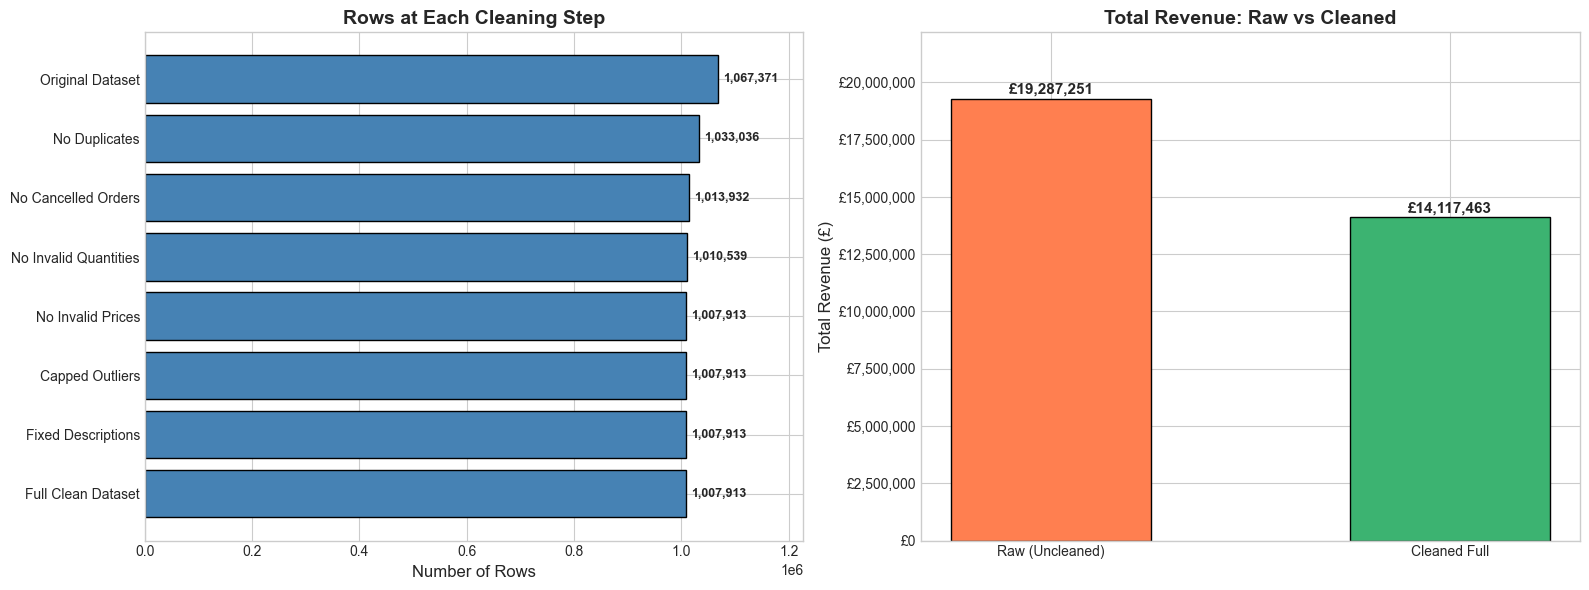

In [11]:
# ============================================
# BEFORE vs AFTER COMPARISON (FIXED)
# ============================================

print("\n📊 CLEANING SUMMARY - BEFORE vs AFTER:")
print("=" * 70)

# Create comparison table
print(f"\n{'Step':<40} {'Rows':>12} {'Removed':>12}")
print("-" * 70)

for i, (step, count) in enumerate(cleaning_log):
    if i == 0:
        removed = "-"
    else:
        removed = f"-{cleaning_log[i-1][1] - count:,}"
    print(f"   {step:<38} {count:>10,} {removed:>12}")

print("-" * 70)
total_removed = cleaning_log[0][1] - cleaning_log[-2][1]  # Full clean
print(f"   {'TOTAL REMOVED (Full Dataset)':<38} {cleaning_log[-2][1]:>10,} {f'-{total_removed:,}':>12}")
print(f"   {'Percentage Kept':<38} {cleaning_log[-2][1]/cleaning_log[0][1]*100:>9.1f}%")
print("=" * 70)

# Visual comparison
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# LEFT: Row count at each cleaning step (automatically take step names from log)
plot_logs = cleaning_log[:-1]  # Exclude customer split for this bar chart
step_names = [log[0].replace("After Removing ", "No ").replace("After Fixing ", "Fixed ").replace("After Capping ", "Capped ") for log in plot_logs]
counts = [log[1] for log in plot_logs]

bars = axes[0].barh(step_names, counts, color='steelblue', edgecolor='black')
axes[0].set_xlabel('Number of Rows', fontsize=12)
axes[0].set_title('Rows at Each Cleaning Step', fontsize=14, fontweight='bold')
axes[0].invert_yaxis()

for bar, count in zip(bars, counts):
    axes[0].text(bar.get_width() + 10000, bar.get_y() + bar.get_height()/2,
                 f'{count:,}', va='center', fontsize=9, fontweight='bold')

axes[0].set_xlim(0, max(counts) * 1.15)

# RIGHT: Revenue comparison
rev_before = pd.read_parquet(parquet_path)
rev_before_val = (rev_before['Quantity'] * rev_before['Price']).sum()
rev_after_val = df_full['Revenue'].sum()

axes[1].bar(['Raw (Uncleaned)', 'Cleaned Full'], 
            [rev_before_val, rev_after_val],
            color=['coral', 'mediumseagreen'], edgecolor='black', width=0.5)
axes[1].set_ylabel('Total Revenue (£)', fontsize=12)
axes[1].set_title('Total Revenue: Raw vs Cleaned', fontsize=14, fontweight='bold')
axes[1].yaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f'£{x:,.0f}'))

for i, v in enumerate([rev_before_val, rev_after_val]):
    axes[1].text(i, v + 200000, f'£{v:,.0f}', ha='center', fontsize=11, fontweight='bold')

axes[1].set_ylim(0, max(rev_before_val, rev_after_val) * 1.15)

plt.tight_layout()
os.makedirs(os.path.join(project_root, "reports", "figures"), exist_ok=True)
plt.savefig(os.path.join(project_root, "reports", "figures", "cleaning_comparison.png"), 
            dpi=150, bbox_inches='tight')
plt.show()

In [12]:
# ============================================
# SAVE CLEANED DATASETS
# ============================================

print("💾 SAVING CLEANED DATASETS...")
print("=" * 50)

processed_dir = os.path.join(project_root, "data", "processed")

# --- Save Full Clean Dataset ---
# CSV
full_csv = os.path.join(processed_dir, "cleaned_full.csv")
df_full.to_csv(full_csv, index=False)
print(f"   ✅ Full Clean CSV:      {full_csv}")
print(f"      Size: {os.path.getsize(full_csv)/(1024*1024):.1f} MB")

# Parquet
full_parquet = os.path.join(processed_dir, "cleaned_full.parquet")
df_full.to_parquet(full_parquet, index=False, engine='pyarrow')
print(f"   ✅ Full Clean Parquet:  {full_parquet}")
print(f"      Size: {os.path.getsize(full_parquet)/(1024*1024):.1f} MB")
print()

# --- Save Customer Clean Dataset ---
# CSV
cust_csv = os.path.join(processed_dir, "cleaned_customers.csv")
df_customers.to_csv(cust_csv, index=False)
print(f"   ✅ Customer Clean CSV:      {cust_csv}")
print(f"      Size: {os.path.getsize(cust_csv)/(1024*1024):.1f} MB")

# Parquet
cust_parquet = os.path.join(processed_dir, "cleaned_customers.parquet")
df_customers.to_parquet(cust_parquet, index=False, engine='pyarrow')
print(f"   ✅ Customer Clean Parquet:  {cust_parquet}")
print(f"      Size: {os.path.getsize(cust_parquet)/(1024*1024):.1f} MB")

print()
print("🎉 ALL CLEANED DATASETS SAVED SUCCESSFULLY!")

💾 SAVING CLEANED DATASETS...
   ✅ Full Clean CSV:      d:\Zudio Internship\Project 1\RetailPulse\data\processed\cleaned_full.csv
      Size: 95.5 MB
   ✅ Full Clean Parquet:  d:\Zudio Internship\Project 1\RetailPulse\data\processed\cleaned_full.parquet
      Size: 7.3 MB

   ✅ Customer Clean CSV:      d:\Zudio Internship\Project 1\RetailPulse\data\processed\cleaned_customers.csv
      Size: 73.8 MB
   ✅ Customer Clean Parquet:  d:\Zudio Internship\Project 1\RetailPulse\data\processed\cleaned_customers.parquet
      Size: 5.8 MB

🎉 ALL CLEANED DATASETS SAVED SUCCESSFULLY!


In [13]:
# ============================================
# FINAL DATA QUALITY VERIFICATION
# ============================================

print("🔍 FINAL DATA QUALITY CHECK:")
print("=" * 70)

# Check Full Dataset
print("\n📊 FULL CLEAN DATASET:")
print(f"   Shape: {df_full.shape[0]:,} rows × {df_full.shape[1]} columns")
print(f"   Missing values: {df_full.isnull().sum().sum():,}")
print(f"   Negative quantities: {(df_full['Quantity'] < 0).sum():,}")
print(f"   Zero quantities: {(df_full['Quantity'] == 0).sum():,}")
print(f"   Negative prices: {(df_full['Price'] < 0).sum():,}")
print(f"   Zero prices: {(df_full['Price'] == 0).sum():,}")
print(f"   Cancelled invoices: {df_full['Invoice'].str.startswith('C').sum():,}")
print(f"   Date range: {df_full['InvoiceDate'].min().date()} to {df_full['InvoiceDate'].max().date()}")
print(f"   Revenue range: £{df_full['Revenue'].min():.2f} to £{df_full['Revenue'].max():.2f}")

# Check Customer Dataset
print("\n📊 CUSTOMER CLEAN DATASET:")
print(f"   Shape: {df_customers.shape[0]:,} rows × {df_customers.shape[1]} columns")
print(f"   Missing values: {df_customers.isnull().sum().sum():,}")
print(f"   Missing Customer IDs: {df_customers['Customer ID'].isna().sum():,}")
print(f"   Unique Customers: {df_customers['Customer ID'].nunique():,}")
print(f"   Date range: {df_customers['InvoiceDate'].min().date()} to {df_customers['InvoiceDate'].max().date()}")

# Quick statistics
print("\n📊 KEY STATISTICS (Full Dataset):")
print(f"   Total Revenue:    £{df_full['Revenue'].sum():,.2f}")
print(f"   Avg Order Value:  £{df_full.groupby('Invoice')['Revenue'].sum().mean():.2f}")
print(f"   Total Products:   {df_full['StockCode'].nunique():,}")
print(f"   Total Countries:  {df_full['Country'].nunique()}")

print("\n" + "=" * 70)
print("  ✅ DATA CLEANING COMPLETE!")
print("  Both datasets are ready for machine learning!")
print("=" * 70)

🔍 FINAL DATA QUALITY CHECK:

📊 FULL CLEAN DATASET:
   Shape: 1,007,913 rows × 9 columns
   Missing values: 228,488
   Negative quantities: 0
   Zero quantities: 0
   Negative prices: 0
   Zero prices: 0
   Cancelled invoices: 0
   Date range: 2009-12-01 to 2011-12-09
   Revenue range: £0.00 to £240.82

📊 CUSTOMER CLEAN DATASET:
   Shape: 779,425 rows × 9 columns
   Missing values: 0
   Missing Customer IDs: 0
   Unique Customers: 5,878
   Date range: 2009-12-01 to 2011-12-09

📊 KEY STATISTICS (Full Dataset):
   Total Revenue:    £14,117,463.24
   Avg Order Value:  £352.26
   Total Products:   4,917
   Total Countries:  43

  ✅ DATA CLEANING COMPLETE!
  Both datasets are ready for machine learning!
